**Estimated time to read:** 15-20 minutes
**Depends on:** Setup and Orientation, Data Ingestion
**Unlocks:** Annotation and Classification with JABS

This is where Data Ingestion comes together at scale. You load pre-computed pose for **many** sessions, apply concrete quality-control (QC) metrics, and produce a filtered list of trustworthy sessions that feeds the behavior-classification step next.

> **Data note.** This notebook auto-selects its data: the **full extracted dataset** (`data/zenodo/jabs_grooming/`) if present, otherwise the small **committed toy sample** in `data/toy/` - so it runs on a fresh clone and in CI. The `data_subdir` parameter can force a specific `data/` subfolder. The QC code is identical regardless of source.


## Learning Goals

By the end of this page, you should be able to:

- Explain why pose quality control has to happen before behavior classification, not after
- Recognize common pose failure modes - occlusion, tracking dropout, stuck keypoints, camera artifacts - from their signal in the data
- Apply concrete QC thresholds to produce a filtered list of trustworthy sessions, and justify the parameters you chose
- Compare a high- and a low-confidence session and explain what is actually different between them


## Why Quality Control Matters

JABS classifies behavior from features computed on the pose keypoints. If the pose is wrong, the classifier learns from noise instead of behavior. So before annotating anything, we ask which sessions are trustworthy.

> So a confidence value is not an abstract score - it is literally how tall the most likely spot is:
>
> - A sharp, tall peak means the model is sure: one clear location. High confidence.
> - A flat, diffuse map means the model has no clear answer. Low confidence.
>
> This is why a threshold like 0.3 is meaningful: below it, the map had no real peak, so the predicted point is little better than a guess. Precomputed Tracking & QC uses exactly this idea to decide which frames and keypoints to trust. Let's make it concrete.
>
> - from the [Pose Estimation deep dive](02_pose_estimation.html)

Three things to keep in mind:

1. Even a strong pose model produces some low-confidence frames.
2. QC is **not** about throwing data away. It is about knowing where to trust the data and where not to.
3. The thresholds you pick are a scientific choice: too strict and you discard useful sessions; too lenient and the classifier learns from noisy pose.


## Common Failure Modes

When you scan pose quality, these are the patterns to look for:

| Failure mode | Signal in the data | Likely cause |
|---|---|---|
| Mouse absent | All keypoints low-confidence across many consecutive frames | Mouse hiding in a corner, or removed early |
| Keypoint occlusion | One keypoint (e.g. a paw) persistently low confidence | Body part hidden by the body |
| Tracking dropout | Confidence drops abruptly, then recovers | Motion blur, lighting change |
| Stuck keypoint | (y, x) constant for many frames despite high confidence | Model failure mode |
| Camera artifact | Systematic bias in position | Arena not registered correctly |

Some of these are expected and fine (a mouse hiding briefly); others (a stuck keypoint, a camera artifact) signal a real problem. QC is about telling them apart.

In [1]:
# Why: knobs papermill/CI can override without editing the notebook body -
# these three values define what "trustworthy" means for the rest of this page.
# parameters
data_subdir = ""             # data/ subfolder to read; "" = auto (full dataset if present, else committed toy). papermill/CI can override.
low_conf_threshold = 0.3     # a frame is "low confidence" if its mean keypoint confidence is below this
max_low_conf_pct = 0.20      # flag a session if more than 20% of its frames are low confidence
min_frames = 500            # flag a session shorter than this (likely truncated)


## Load All Sessions

Load every pose file and build a one-row-per-session summary: frame count, mean confidence, the fraction of low-confidence frames, and the mean confidence of each keypoint.

In [2]:
# Why: load every session's pose summary at once (not just one file), since
# QC is a property of the whole dataset, not a single session.
import json
from pathlib import Path

import cv2
import h5py
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from jabs.core.abstract.pose_est import PoseEstimation

# Locate the project root - a straight walk-up from the working directory
# looking for requirements.txt + student_notebooks/. This page is built once
# via papermill from the repo root, so that is the only path that matters.
current = Path.cwd().resolve()
for _ in range(10):
    if (current / "requirements.txt").exists() and (current / "student_notebooks").is_dir():
        project_root = current
        break
    current = current.parent
else:
    raise RuntimeError(
        "Could not find project root. Run this notebook from within the repo."
    )

# Same two-tier auto-detection as Data Ingestion / Pose Estimation.
_zenodo = project_root / "data" / "zenodo" / "jabs_grooming"
if data_subdir:
    data_dir = project_root / "data" / data_subdir
elif list(_zenodo.glob("*_pose_est_v6.h5")):
    data_dir = _zenodo
else:
    data_dir = project_root / "data" / "toy"

# Derive keypoint names from the JABS package definition (stays in sync automatically).
KEYPOINT_NAMES = [k.name.lower() for k in PoseEstimation.KeypointIndex]

pose_files = sorted(data_dir.glob("*_pose_est_v*.h5"))
if not pose_files:
    raise FileNotFoundError(
        f"No pose files in {data_dir}.\n"
        "Run: python student_scripts/download_zenodo.py --extract"
    )
print(f"Found {len(pose_files)} session(s) in {data_dir}\n")

# One row per session: overall QC stats plus per-keypoint mean confidence
# (the per-keypoint numbers feed the reliability chart below).
records = []
for pose_path in pose_files:
    with h5py.File(str(pose_path), "r") as f:
        confidence = f["poseest/confidence"][:, 0, :]  # (n_frames, 12), drop animal axis

    n_frames = confidence.shape[0]
    per_frame_mean = confidence.mean(axis=1)
    pct_low_conf = float((per_frame_mean < low_conf_threshold).mean())

    record = {
        "file": pose_path.name,
        "subject_id": pose_path.stem.split("_pose_est")[0],
        "n_frames": n_frames,
        "mean_conf": round(float(confidence.mean()), 4),
        "pct_low_conf": round(pct_low_conf, 4),
    }
    for kp_idx, kp in enumerate(KEYPOINT_NAMES):
        record[f"conf_{kp}"] = round(float(confidence[:, kp_idx].mean()), 4)
    records.append(record)

summary_df = pd.DataFrame(records)
print(f"Sessions loaded: {len(summary_df)}")
print(f"Mean confidence across sessions: {summary_df['mean_conf'].mean():.3f}")
summary_df[["file", "n_frames", "mean_conf", "pct_low_conf"]]

Found 25 session(s) in getting-started-with-jabs\data\zenodo\jabs_grooming

Sessions loaded: 25
Mean confidence across sessions: 0.930


,file,n_frames,mean_conf,pct_low_conf
0,2001_pose_est_v6.h5,2469,0.8660,0.0
1,2002_pose_est_v6.h5,2298,0.9108,0.0
2,2003_pose_est_v6.h5,2636,0.9209,0.0
3,2004_pose_est_v6.h5,996,0.9391,0.0
4,2005_pose_est_v6.h5,1548,0.9322,0.0
5,2006_pose_est_v6.h5,3421,0.9095,0.0
6,2007_pose_est_v6.h5,10788,0.9579,0.0
7,2008_pose_est_v6.h5,614,0.9605,0.0
8,2009_pose_est_v6.h5,912,0.9225,0.0
9,2010_pose_est_v6.h5,1491,0.9250,0.0


## Session-level QC Overview

How the QC metrics are distributed across sessions. At a glance: are any sessions unusually low-confidence, short, or noisy?

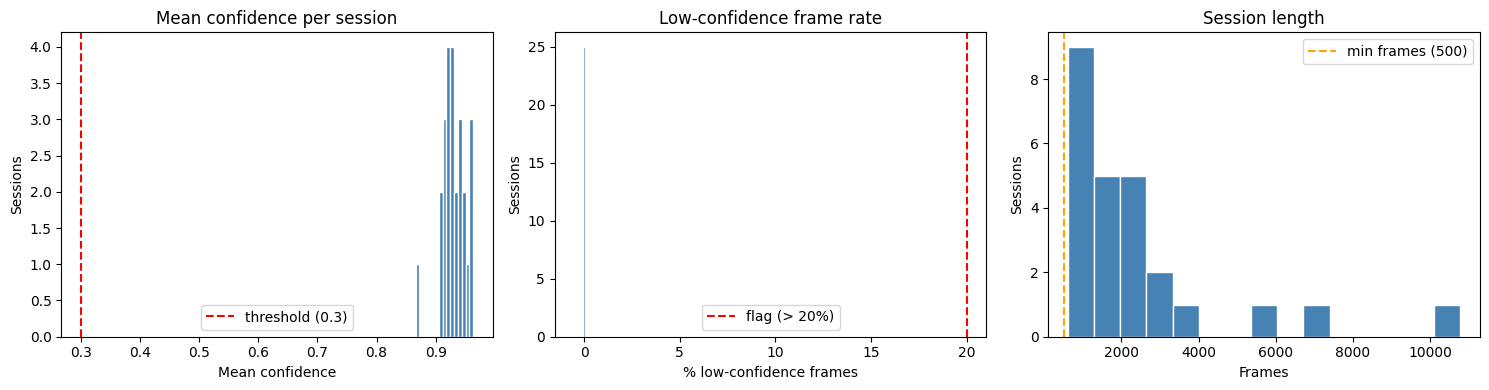

Sessions over the low-confidence flag (20%): 0 / 25


In [3]:
# Why: see the shape of each QC metric across all sessions at a glance -
# a few outliers vs. a smooth spread mean very different things.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(summary_df["mean_conf"], bins=15, color="steelblue", edgecolor="white")
axes[0].axvline(low_conf_threshold, color="red", linestyle="--",
                label=f"threshold ({low_conf_threshold})")
axes[0].set_xlabel("Mean confidence")
axes[0].set_ylabel("Sessions")
axes[0].set_title("Mean confidence per session")
axes[0].legend()

axes[1].hist(summary_df["pct_low_conf"] * 100, bins=15, color="steelblue", edgecolor="white")
axes[1].axvline(max_low_conf_pct * 100, color="red", linestyle="--",
                label=f"flag (> {max_low_conf_pct*100:.0f}%)")
axes[1].set_xlabel("% low-confidence frames")
axes[1].set_ylabel("Sessions")
axes[1].set_title("Low-confidence frame rate")
axes[1].legend()

axes[2].hist(summary_df["n_frames"], bins=15, color="steelblue", edgecolor="white")
axes[2].axvline(min_frames, color="orange", linestyle="--",
                label=f"min frames ({min_frames})")
axes[2].set_xlabel("Frames")
axes[2].set_ylabel("Sessions")
axes[2].set_title("Session length")
axes[2].legend()

plt.tight_layout()
plt.show()

n_flagged = int((summary_df["pct_low_conf"] > max_low_conf_pct).sum())
print(f"Sessions over the low-confidence flag ({max_low_conf_pct*100:.0f}%): "
      f"{n_flagged} / {len(summary_df)}")

> **Quick check:** Before reading on - what shape would you *want* these three histograms to have, and why? What would a histogram shape tell you that a single summary number (like the mean) would hide?


## Per-keypoint Reliability

Which keypoints are systematically less reliable across the whole subset? (This reflects how hard each landmark is to localize - see the Pose Estimation deep dive for more.)

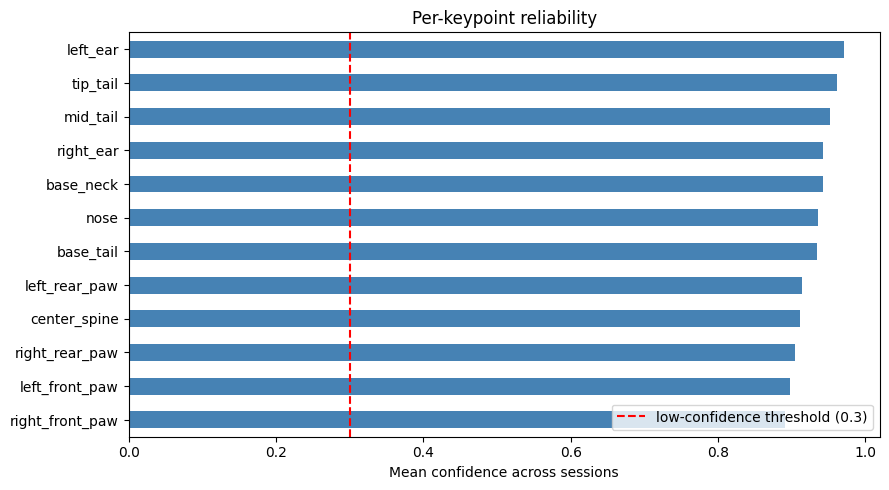

Least reliable keypoints:
right_front_paw    0.890
left_front_paw     0.898
right_rear_paw     0.905
center_spine       0.912


In [4]:
# Why: some keypoints are systematically harder to track than others -
# rank them so that pattern is visible, not buried in per-session averages.
kp_cols = [f"conf_{kp}" for kp in KEYPOINT_NAMES]
kp_means = summary_df[kp_cols].mean()
kp_means.index = KEYPOINT_NAMES
kp_means = kp_means.sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
kp_means.plot(kind="barh", ax=ax, color="steelblue")
ax.axvline(low_conf_threshold, color="red", linestyle="--",
           label=f"low-confidence threshold ({low_conf_threshold})")
ax.set_xlabel("Mean confidence across sessions")
ax.set_title("Per-keypoint reliability")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Least reliable keypoints:")
print(kp_means.head(4).round(3).to_string())


> **Quick check:** Which keypoints perform worst here? If you were reviewing this with a labmate, what would you ask about the recording setup - arena design, camera angle, lighting, coat color - that could explain why those particular keypoints are harder to track?


## Inspect the Lowest-confidence Session

Take the session with the lowest mean confidence and look closer: how does confidence vary over time, and does the mouse move (a quick sanity check that the model is tracking a real animal)?

Lowest-confidence session: 2001_pose_est_v6.h5
  mean confidence:   0.866
  % low-conf frames: 0.0%
  frames:            2469


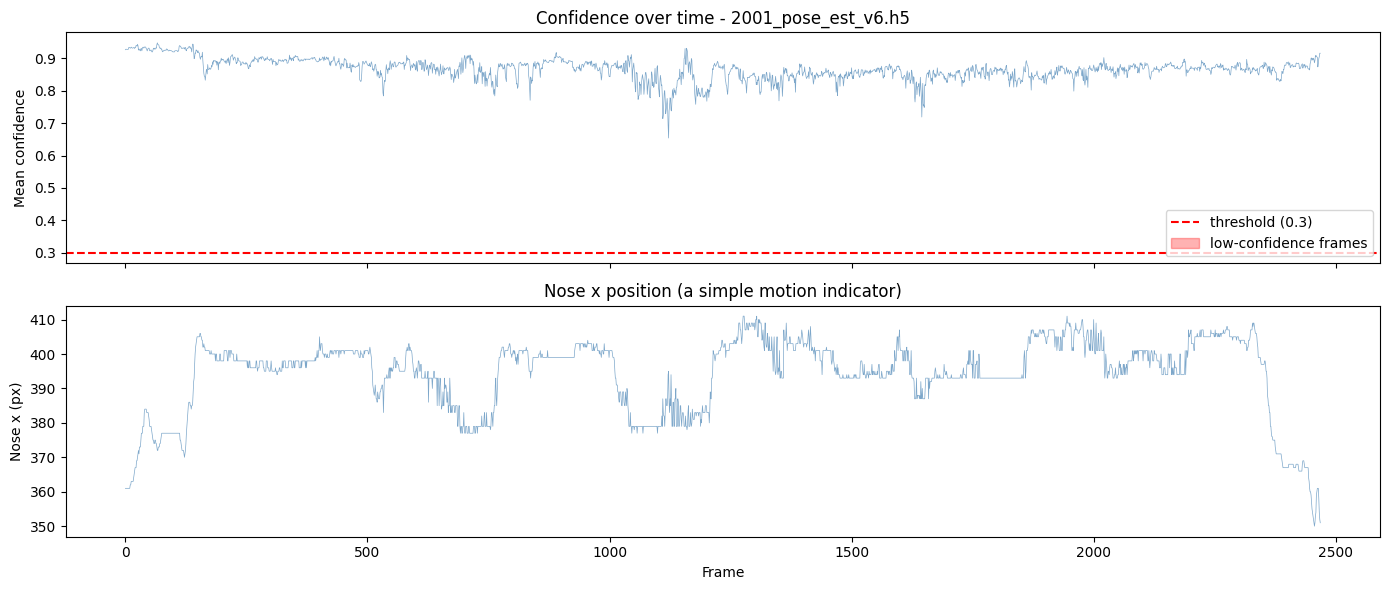

In [5]:
# Why: sanity-check the single worst session by eye - a low average could
# mean uniformly noisy pose, or a few bad stretches in an otherwise fine clip.
worst = summary_df.nsmallest(1, "mean_conf").iloc[0]
worst_path = data_dir / worst["file"]
print(f"Lowest-confidence session: {worst['file']}")
print(f"  mean confidence:   {worst['mean_conf']:.3f}")
print(f"  % low-conf frames: {worst['pct_low_conf']*100:.1f}%")
print(f"  frames:            {worst['n_frames']}")

with h5py.File(str(worst_path), "r") as f:
    points = f["poseest/points"][:, 0, :, :]       # (n_frames, 12, 2) [y, x]
    confidence = f["poseest/confidence"][:, 0, :]  # (n_frames, 12)

per_frame_mean = confidence.mean(axis=1)
nose_idx = KEYPOINT_NAMES.index("nose")
nose_x = points[:, nose_idx, 1]  # x is index 1 in [y, x]

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

axes[0].plot(per_frame_mean, color="steelblue", alpha=0.7, linewidth=0.5)
axes[0].axhline(low_conf_threshold, color="red", linestyle="--",
                label=f"threshold ({low_conf_threshold})")
axes[0].fill_between(np.arange(len(per_frame_mean)), per_frame_mean,
                     where=(per_frame_mean < low_conf_threshold),
                     color="red", alpha=0.3, label="low-confidence frames")
axes[0].set_ylabel("Mean confidence")
axes[0].set_title(f"Confidence over time - {worst['file'][:40]}")
axes[0].legend(loc="lower right")

axes[1].plot(nose_x, color="steelblue", alpha=0.7, linewidth=0.5)
axes[1].set_ylabel("Nose x (px)")
axes[1].set_xlabel("Frame")
axes[1].set_title("Nose x position (a simple motion indicator)")

plt.tight_layout()
plt.show()


> **Quick check:** Pull up the actual video for this session (the matching `.avi` file in the data directory) and watch the frames around the confidence dips flagged above. Is the model just guessing, or is something happening to the animal - grooming, occlusion, leaving the frame - that would explain the drop?


## Apply QC Thresholds and Export

Apply the criteria from the parameters cell and write `qc_passed_sessions.json` - the functional output that the Live Workflow page consumes.

In [6]:
# Why: turn the per-session metrics above into a pass/fail decision, and
# write the passing session list to the file the Live Workflow reads.
qc_mask = (
    (summary_df["pct_low_conf"] <= max_low_conf_pct)
    & (summary_df["n_frames"] >= min_frames)
)
passed = summary_df[qc_mask]
failed = summary_df[~qc_mask]

print(f"Passed: {len(passed)} / {len(summary_df)} sessions")
print(f"Failed: {len(failed)} / {len(summary_df)} sessions")
if len(failed):
    print("\nFailed sessions:")
    print(failed[["file", "n_frames", "mean_conf", "pct_low_conf"]].to_string(index=False))

output = {
    "qc_parameters": {
        "low_conf_threshold": low_conf_threshold,
        "max_low_conf_pct": max_low_conf_pct,
        "min_frames": min_frames,
    },
    "passed_sessions": [
        {"file": r["file"], "subject_id": r["subject_id"]}
        for _, r in passed.iterrows()
    ],
}

output_path = data_dir / "qc_passed_sessions.json"
output_path.write_text(json.dumps(output, indent=2), encoding="utf-8")
print(f"\nWrote {output_path}")
print("The Live Workflow page uses this list to initialize the JABS project.")

Passed: 25 / 25 sessions
Failed: 0 / 25 sessions

Wrote getting-started-with-jabs\data\zenodo\jabs_grooming\qc_passed_sessions.json
The Live Workflow page uses this list to initialize the JABS project.


> **Quick check:** Why these specific threshold values (`low_conf_threshold = 0.3`, `max_low_conf_pct = 0.20`, `min_frames = 500`)? Would a stricter or looser choice change which sessions pass on this data? Is expressing "trustworthy" as three independent thresholds the right parameterization, or would a single combined score behave better (see the Challenge Questions below)?


## Highest vs. Lowest Confidence Session

A representative frame from the highest- and lowest-confidence sessions, drawn as a skeleton with keypoints colored by confidence. This is the clearest picture of what QC protects against. (We plot from the pose data directly - the videos are not needed.)

In [7]:
# Why: turn the JABS chain definition into (start, end) keypoint pairs once, so
# every skeleton plot below can reuse it.
# Build skeleton edges from the JABS package chain definition.
#
# PoseEstimation.FULL_CONNECTED_SEGMENTS is a list of chains. Each chain is a
# sequence of keypoint indices connected in order - like beads on a string.
# We convert each consecutive pair within a chain into a named (start, end) edge.
#
# Printing both the raw chains and the final edge list lets you verify the
# skeleton matches the anatomy you expect before any plotting happens.

print("FULL_CONNECTED_SEGMENTS chains:")
for i, chain in enumerate(PoseEstimation.FULL_CONNECTED_SEGMENTS):
    chain_str = " -> ".join(KEYPOINT_NAMES[int(k)] for k in chain)
    print(f"  chain {i}: {chain_str}")

SKELETON_EDGES = [
    (KEYPOINT_NAMES[int(s)], KEYPOINT_NAMES[int(e)])
    for chain in PoseEstimation.FULL_CONNECTED_SEGMENTS
    for s, e in zip(chain, chain[1:])
]

print(f"SKELETON_EDGES ({len(SKELETON_EDGES)} edges):")
for src, dst in SKELETON_EDGES:
    print(f"  {src:20s} -> {dst}")


FULL_CONNECTED_SEGMENTS chains:
  chain 0: left_front_paw -> center_spine -> right_front_paw
  chain 1: left_rear_paw -> base_tail -> right_rear_paw
  chain 2: nose -> base_neck -> center_spine -> base_tail -> mid_tail -> tip_tail
  chain 3: left_ear -> nose -> right_ear
SKELETON_EDGES (11 edges):
  left_front_paw       -> center_spine
  center_spine         -> right_front_paw
  left_rear_paw        -> base_tail
  base_tail            -> right_rear_paw
  nose                 -> base_neck
  base_neck            -> center_spine
  center_spine         -> base_tail
  base_tail            -> mid_tail
  mid_tail             -> tip_tail
  left_ear             -> nose
  nose                 -> right_ear


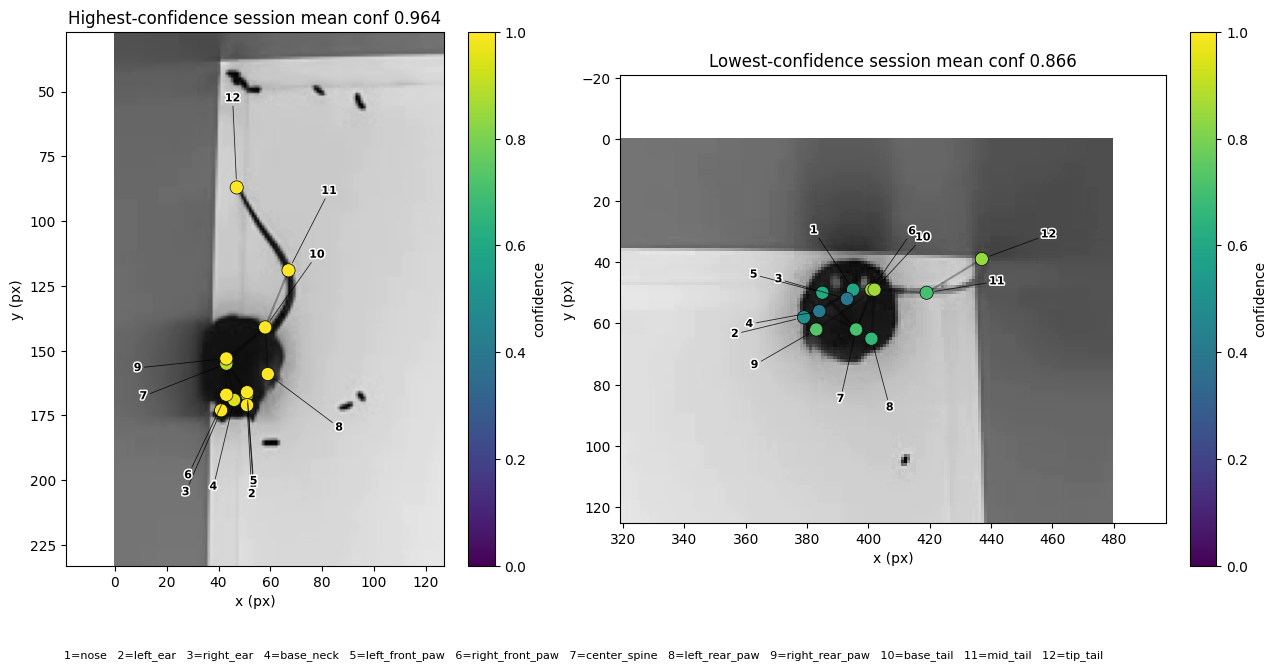

In [8]:
# Why: put the best- and worst-confidence sessions side by side on the real
# video, so "low confidence" has a concrete visual meaning, not just a number.
best = summary_df.nlargest(1, "mean_conf").iloc[0]
worst = summary_df.nsmallest(1, "mean_conf").iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 6.8))
for ax, session, label, pick in [
    (axes[0], best, "Highest-confidence session", "max"),
    (axes[1], worst, "Lowest-confidence session", "min"),
]:
    pose_path = data_dir / session["file"]
    with h5py.File(str(pose_path), "r") as f:
        pts = f["poseest/points"][:, 0, :, :]       # (n, 12, 2) [y, x]
        conf = f["poseest/confidence"][:, 0, :]      # (n, 12)

    per_frame_mean = conf.mean(axis=1)
    frame_idx = int(per_frame_mean.argmax() if pick == "max" else per_frame_mean.argmin())

    xs = pts[frame_idx, :, 1]  # x = index 1
    ys = pts[frame_idx, :, 0]  # y = index 0

    # Draw the source video frame behind the skeleton, cropped to the mouse,
    # so low- and high-confidence sessions can be compared against the animal
    # itself rather than just against each other's points.
    video_path = pose_path.parent / (pose_path.name.split("_pose_est")[0] + ".avi")
    if video_path.exists():
        cap = cv2.VideoCapture(str(video_path))
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
        ok, frame_bgr = cap.read()
        cap.release()
        if ok:
            frame_img = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
            ax.imshow(frame_img)
            pad = 60
            # xs/ys are uint16 from the HDF5 file - cast to int before arithmetic,
            # or subtracting pad underflows and wraps around to a huge value.
            ax.set_xlim(int(xs.min()) - pad, int(xs.max()) + pad)
            ax.set_ylim(int(ys.max()) + pad, int(ys.min()) - pad)

    for src, dst in SKELETON_EDGES:
        si, di = KEYPOINT_NAMES.index(src), KEYPOINT_NAMES.index(dst)
        ax.plot([xs[si], xs[di]], [ys[si], ys[di]], "k-", alpha=0.3, linewidth=1.5)

    # viridis (not a red-green diverging scale) reads correctly for
    # red-green colorblind viewers and is what the Pose Estimation deep
    # dive already uses for confidence, so this stays consistent with it.
    sc = ax.scatter(xs, ys, c=np.clip(conf[frame_idx, :], 0, 1),
                    cmap="viridis", vmin=0, vmax=1, s=90, zorder=5,
                    edgecolor="black", linewidth=0.5)
    # Number each point instead of labeling it with its full name - color is
    # already used for confidence, and 12 text labels on a cropped, curled-up
    # mouse overlap into an unreadable pile. A shared legend below the figure
    # maps number -> keypoint name once for both panels.
    #
    # Labels sit outside the points with a leader line, radiating outward from
    # the cluster centroid - the mouse is often curled up, so points near the
    # center get pushed out along their own direction rather than all crowding
    # into the same small area.
    cx, cy = float(xs.mean()), float(ys.mean())
    spread = max(int(xs.max()) - int(xs.min()), int(ys.max()) - int(ys.min()), 1)
    leader_len = spread * 0.4
    for i, (x, y) in enumerate(zip(xs, ys)):
        dx, dy = float(x) - cx, float(y) - cy
        dist = np.hypot(dx, dy)
        ux, uy = (dx / dist, dy / dist) if dist > 1e-6 else (np.cos(i), np.sin(i))
        label_xy = (x + ux * leader_len, y + uy * leader_len)
        ax.annotate(str(i + 1), xy=(x, y), xytext=label_xy,
                    fontsize=8, fontweight="bold", ha="center", va="center",
                    color="black", zorder=6,
                    path_effects=[pe.withStroke(linewidth=2.2, foreground="white")],
                    arrowprops=dict(arrowstyle="-", color="black", lw=0.6,
                                     alpha=0.8, shrinkA=0, shrinkB=6))
    fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04, label="confidence")
    ax.set_aspect("equal")
    if not video_path.exists():
        ax.invert_yaxis()  # no frame to anchor to; still flip to the image convention
    ax.set_title(f"{label} mean conf {session['mean_conf']:.3f}")
    ax.set_xlabel("x (px)")
    ax.set_ylabel("y (px)")

plt.tight_layout()
kp_legend = "   ".join(f"{i + 1}={name}" for i, name in enumerate(KEYPOINT_NAMES))
fig.subplots_adjust(bottom=0.16)
fig.text(0.5, 0.02, kp_legend, ha="center", va="bottom", fontsize=8)
plt.show()


## What Feeds Into the Live Workflow

The `qc_passed_sessions.json` you just wrote is the direct input to the JABS project setup on the Live Workflow page:

```
all sessions  -->  QC filter (pct_low_conf, min_frames)  -->  qc_passed_sessions.json  -->  JABS project
```

Only QC-passed sessions are offered for annotation. The thresholds in the parameters cell are a scientific decision - change them and the Live Workflow page sees a different set of sessions.

**On this data:** every session here passes these thresholds - that does not mean QC did nothing. The histograms above already show real spread in confidence and session length; nothing here happens to cross the flag line. On other datasets, or with stricter thresholds, some sessions would fail - the point of this page is to give you the tools to notice that when it happens, not a guarantee that it happens here.

## Understanding Checkpoint

1. In your own words: why run QC before behavior classification rather than after?
2. Your QC run passed (or flagged) some sessions. Before excluding a flagged session, what would you want to look at first?
3. One session in the JABS single-mouse behaviors example project has a session-level mean confidence of roughly 0.8 - well above the low-confidence threshold - yet one keypoint returns the exact same pixel coordinate for all 9,000 frames. This session would pass every filter applied above. What signal in the pose data would reveal the stuck keypoint, and how would you detect it programmatically without watching the video?

## Challenge Questions

- Design a single QC score that combines mean confidence, percent low-confidence frames, and session length. What weights would you choose, and how would you check that higher-scoring sessions actually produce better classifiers?
- Paw and tail-tip keypoints are often the least reliable. How could systematically low paw confidence bias a classifier trained to recognize grooming, where paw motion is the defining feature?
- The pose files carry a `cm_per_pixel` attribute. Write a function that converts the nose trajectory to speed in cm/s, apply it to the passing sessions, and describe what the speed distribution says about open-field locomotion.
- A slightly tilted arena would add a systematic bias to every position. Design a diagnostic plot that would catch this before it reaches the classifier.

## What's Next

You loaded pre-computed pose for many sessions, assessed quality, and exported `qc_passed_sessions.json`.

**Next:** the Live Workflow page initializes a JABS project from the QC-passed sessions and walks through annotating a behavior, training a classifier, and generating behavior labels.